# Insist on d = 0.25 for every asset — 2024 → 2026 Q3

Continues `ffd-z-plot2.ipynb`. No d review: **d = 0.25 and τ = 1e-4 are kept for all four assets**, including XAUUSD (compare `ffd-z-plot-xau03.ipynb`, where gold's d was raised to 0.30).

| Item | Setting |
|---|---|
| Method | Fixed-width window FFD on `log(close)`, daily |
| τ / d / FFD window | 1e-4 / **0.25** / 445 bars, every asset |
| Feature | **Rolling Z over 445 bars (= FFD window)**, causal, computed from 2019 data |
| Plot range | **2024-01-01 → 2026-09-30** (test period; 2026 is Jan–Sep only) |
| Train reference | 2021-01-01 → 2023-12-31 |

What we check (from `fracdiff-feature.md`): the model-facing checks, plus ADF as a proxy.

| Check | Question |
|---|---|
| Z outside train range | Does the model see inputs it never saw in train? |
| Z drift | Has Z's yearly mean / σ moved away from train? |
| Clip at ±4 | How often would the guard bite? |
| Raw FFD outside train range | For contrast: what if raw FFD were the feature? |
| ADF on FFD | Proxy only |

Not checked here: the model's own error. There is no model yet; that is Stage B.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from statsmodels.tsa.stattools import adfuller

DATA = Path('../../data')
ASSETS = ['BTC', 'ETH', 'QQQ', 'XAUUSD']
TAU, D = 1e-4, 0.25
Z_MIN, CLIP = 60, 4.0
TRAIN = ('2021-01-01', '2023-12-31')
PLOT_START, PLOT_END = '2024-01-01', '2026-09-30'

def ffd_weights(d, tau=TAU):
    w = [1.0]
    while True:
        k = len(w)
        nxt = -w[-1] * (d - k + 1) / k
        if abs(nxt) < tau:
            return np.asarray(w)
        w.append(nxt)

def ffd(log_close, d=D, tau=TAU):
    w = ffd_weights(d, tau)
    y = np.full(len(log_close), np.nan)
    y[len(w) - 1:] = np.convolve(log_close.values, w, mode='valid')
    return pd.Series(y, index=log_close.index)

def load(sym):
    df = pd.read_parquet(DATA / sym / f'{sym}-sorted-1d.parquet')
    ts = pd.to_datetime(df['timestamp'])
    ts = ts.dt.tz_convert(None) if ts.dt.tz is not None else ts
    assert ts.is_monotonic_increasing and ts.is_unique
    return df.set_axis(ts)['close']

def adf_p(y):
    return adfuller(y.dropna(), maxlag=1, regression='c', autolag=None)[1]

W = len(ffd_weights(D))
frames = {}
for s in ASSETS:
    close = load(s).loc[:PLOT_END]
    f = ffd(np.log(close))
    fa = f.loc[f.first_valid_index():]
    r = fa.rolling(W, min_periods=Z_MIN)
    frames[s] = pd.DataFrame({'close': close, 'ffd': f, 'z': (fa - r.mean()) / r.std(ddof=0)})
W

445

## Price / FFD / rolling Z (2024 → 2026 Q3), with the train range shaded

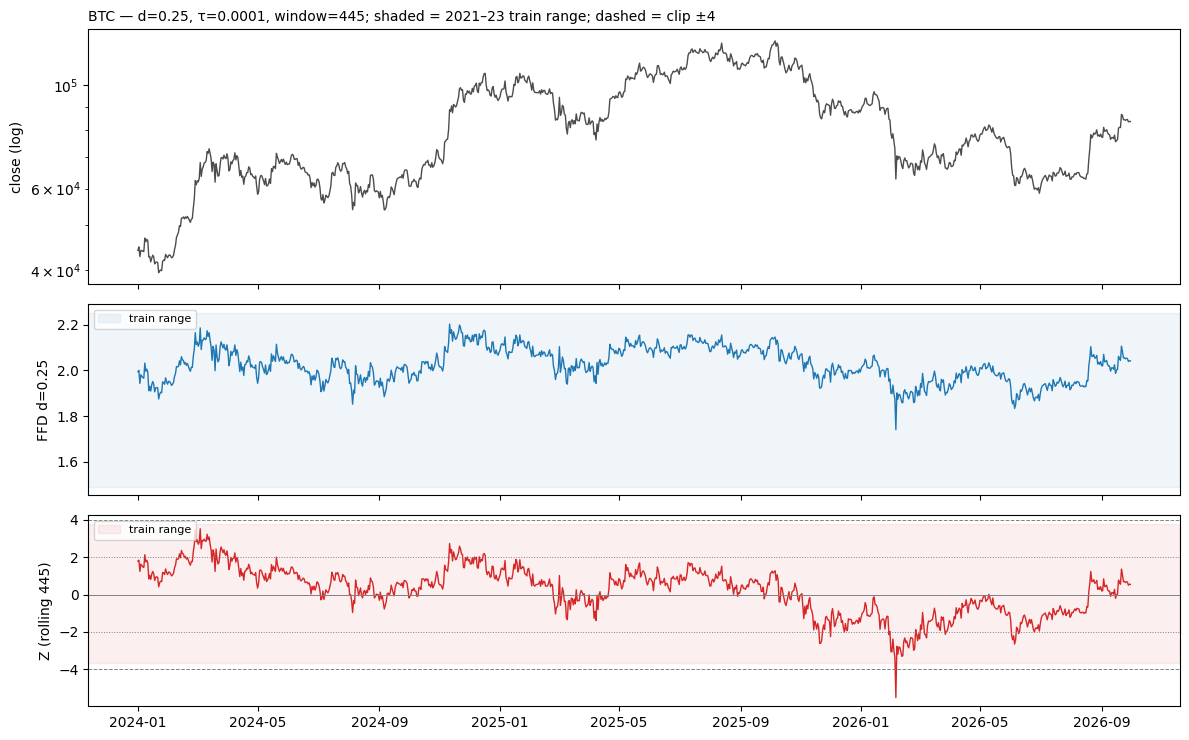

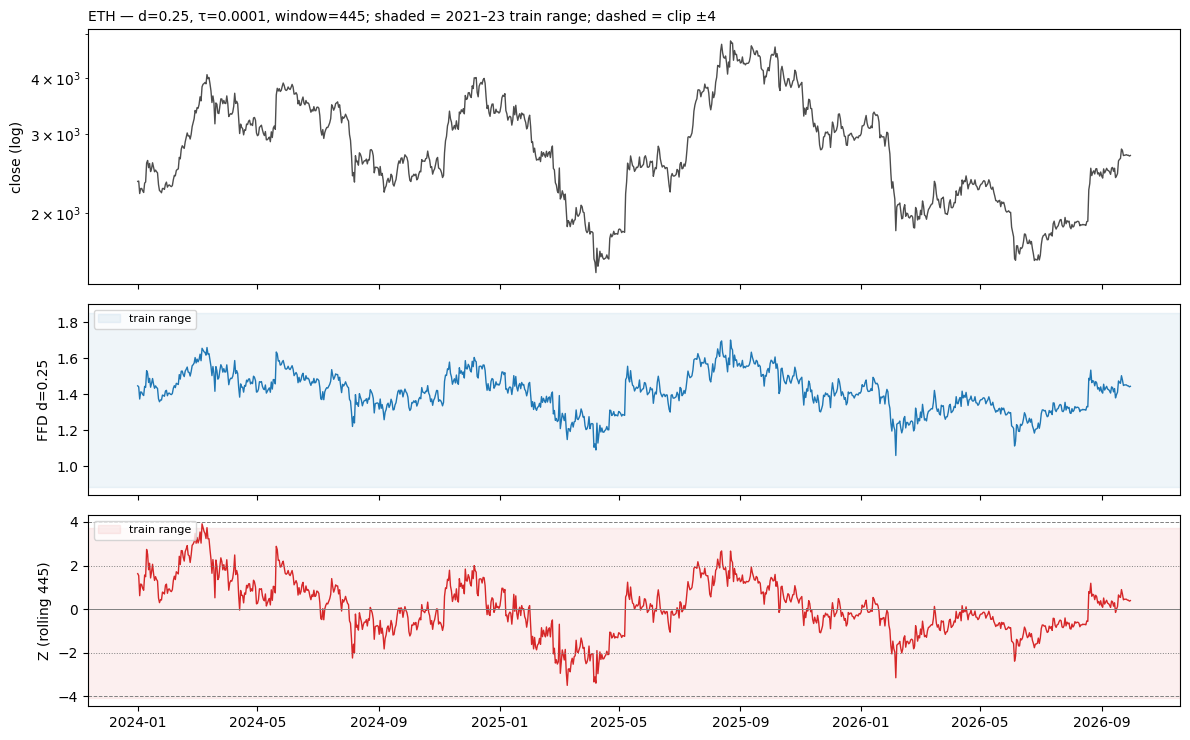

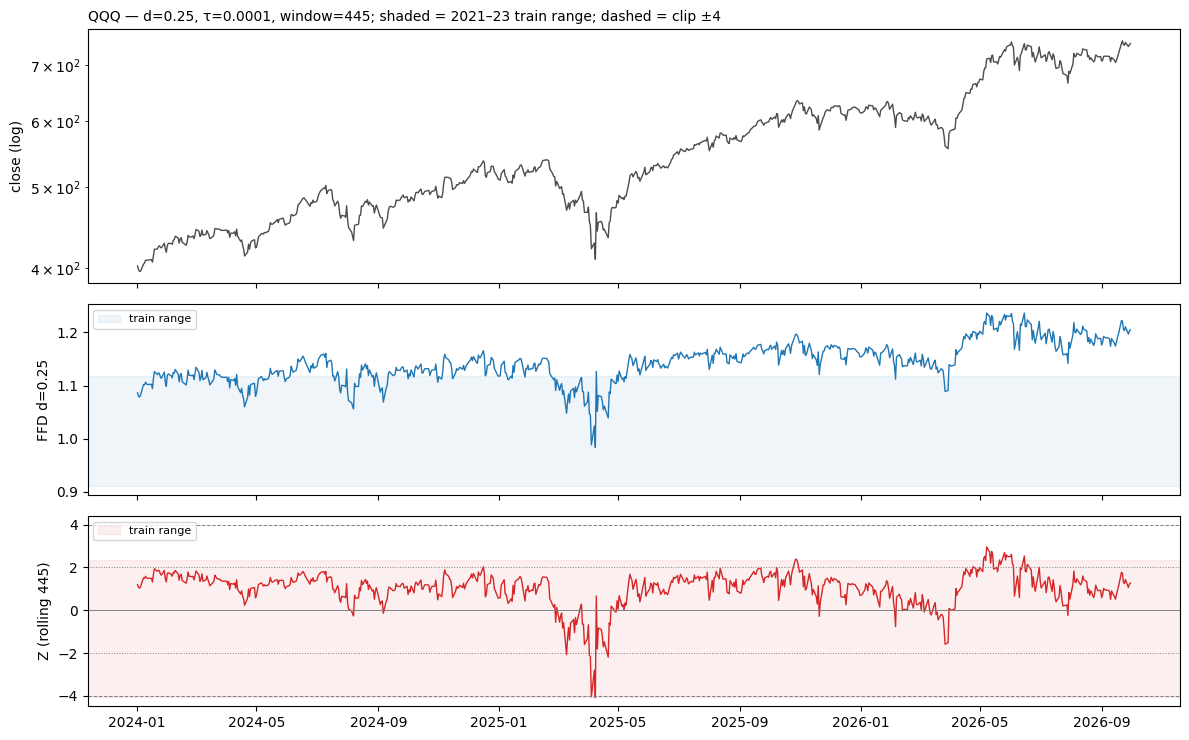

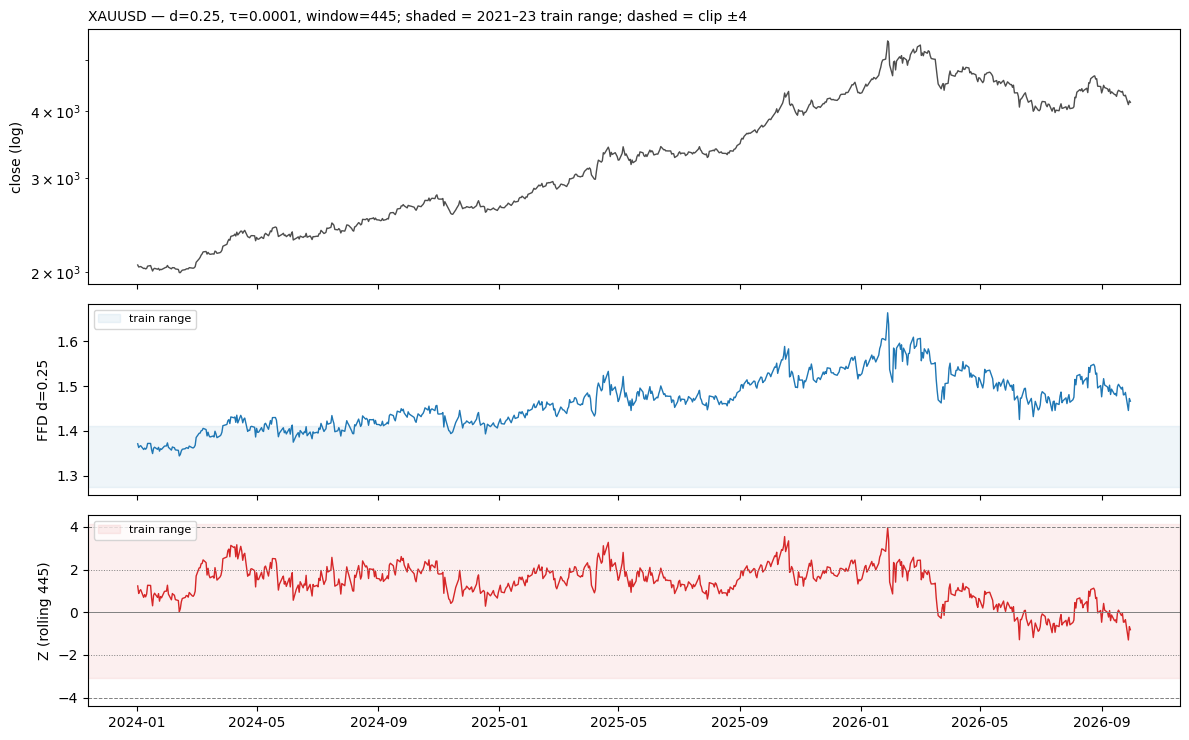

In [2]:
for s in ASSETS:
    df = frames[s]
    tr, te = df.loc[TRAIN[0]:TRAIN[1]], df.loc[PLOT_START:PLOT_END]
    fig, ax = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={'height_ratios': [2, 1.5, 1.5]})
    ax[0].plot(te.index, te.close, color='0.3', lw=1); ax[0].set_yscale('log'); ax[0].set_ylabel('close (log)')
    ax[1].plot(te.index, te.ffd, color='tab:blue', lw=1); ax[1].set_ylabel(f'FFD d={D}')
    ax[1].axhspan(tr.ffd.min(), tr.ffd.max(), color='tab:blue', alpha=0.07, label='train range')
    ax[1].legend(loc='upper left', fontsize=8)
    ax[2].plot(te.index, te.z, color='tab:red', lw=1); ax[2].set_ylabel(f'Z (rolling {W})')
    ax[2].axhspan(tr.z.min(), tr.z.max(), color='tab:red', alpha=0.07, label='train range')
    for lvl, ls in [(0, '-'), (2, ':'), (-2, ':'), (CLIP, '--'), (-CLIP, '--')]:
        ax[2].axhline(lvl, color='0.5', lw=0.7, ls=ls)
    ax[2].legend(loc='upper left', fontsize=8)
    ax[0].set_title(f'{s} — d={D}, τ={TAU:g}, window={W}; shaded = 2021–23 train range; dashed = clip ±{CLIP:g}',
                    loc='left', fontsize=10)
    plt.tight_layout(); plt.show()

## Model-facing checks

In [3]:
rows = []
for s in ASSETS:
    df = frames[s]; tr = df.loc[TRAIN[0]:TRAIN[1]]
    zlo, zhi, flo, fhi = tr.z.min(), tr.z.max(), tr.ffd.min(), tr.ffd.max()
    for y in ['2024', '2025', '2026']:
        t = df.loc[y]
        rows.append({'asset': s, 'year': y,
                     'Z % outside train range': ((t.z < zlo) | (t.z > zhi)).mean() * 100,
                     'Z % beyond clip ±4': (t.z.abs() > CLIP).mean() * 100,
                     'Z mean': t.z.mean(), 'Z σ': t.z.std(),
                     'Z mean (train)': tr.z.mean(), 'Z σ (train)': tr.z.std(),
                     'raw FFD % outside train range': ((t.ffd < flo) | (t.ffd > fhi)).mean() * 100,
                     'ADF p (FFD, year)': adf_p(t.ffd)})
checks = pd.DataFrame(rows).set_index(['asset', 'year'])
checks.round(3)

Z % outside train range  Z % beyond clip ±4  Z mean    Z σ  \
asset  year                                                               
BTC    2024                    0.000               0.000   1.125  0.817   
       2025                    0.000               0.000   0.247  0.947   
       2026                    0.366               0.366  -1.039  0.986   
ETH    2024                    0.273               0.000   0.771  1.156   
       2025                    0.000               0.000  -0.108  1.293   
       2026                    0.000               0.000  -0.593  0.690   
QQQ    2024                    0.000               0.000   1.217  0.413   
       2025                    1.600               0.800   0.834  1.022   
       2026                    6.952               0.000   1.057  0.816   
XAUUSD 2024                    0.000               0.000   1.555  0.641   
       2025                    0.000               0.000   1.722  0.505   
       2026                    0.000               0.000   0.660  1.086   

             Z mean (train)  Z σ (train)  raw FFD % outside train range  \
asset  year                                                               
BTC    2024           0.162        1.248                          0.000   
       2025           0.162        1.248                          0.000   
       2026           0.162        1.248                          0.000   
ETH    2024           0.201        1.217                          0.000   
       2025           0.201        1.217                          0.000   
       2026           0.201        1.217                          0.000   
QQQ    2024          -0.065        1.364                         60.317   
       2025          -0.065        1.364                         78.400   
       2026          -0.065        1.364                         97.861   
XAUUSD 2024           0.013        1.122                         48.649   
       2025           0.013        1.122                        100.000   
       2026           0.013        1.122                        100.000   

             ADF p (FFD, year)  
asset  year                     
BTC    2024              0.028  
       2025              0.016  
       2026              0.054  
ETH    2024              0.010  
       2025              0.082  
       2026              0.040  
QQQ    2024              0.000  
       2025              0.175  
       2026              0.109  
XAUUSD 2024              0.067  
       2025              0.088  
       2026              0.101

In [4]:
# ADF on multi-year windows (proxy)
pd.DataFrame({'2024–25': {s: adf_p(frames[s].ffd.loc['2024':'2025']) for s in ASSETS},
              '2025–26Q3': {s: adf_p(frames[s].ffd.loc['2025':PLOT_END]) for s in ASSETS},
              '2024–26Q3': {s: adf_p(frames[s].ffd.loc['2024':PLOT_END]) for s in ASSETS}}).round(4)

,2024–25,2025–26Q3,2024–26Q3
BTC,0.0004,0.0157,0.0003
ETH,0.0012,0.0079,0.0003
QQQ,0.0020,0.0649,0.0052
XAUUSD,0.2637,0.0052,0.0414


### Reading — insisting on d = 0.25 (2024 → 2026 Q3)

**Gold's trend ended and d = 0.25 recovered on its own.** Gold peaked on 2026-01-28 (about 5,420) and fell back to about 4,160 by September. FFD came back down, and ADF on 2025–26 Q3 passes at 1% (p ≈ 0.005). Rolling Z moved from about +2 to about −1. Raising d at end-2024 (to 0.30) and end-2025 (to about 0.40) would have chased a trend that then ended, at the cost of two retrains and two Z resets.

| Check (2024 → 2026 Q3) | BTC | ETH | QQQ | XAUUSD |
|---|---|---|---|---|
| Z outside train range | 2026: 0.4% (one day, Z ≈ −5.5) | ≤ 0.3% | 2025: 1.6%, 2026: 7% (above train max +2.35, peak ≈ +3.0) | 0% |
| Z beyond clip ±4 | 2026: one day | 0 | 2025: 0.8% | 0 |
| Raw FFD outside train range | 0% | 0% | 60% → 78% → 98% | 49% → 100% → 100% |
| ADF 2024–26 Q3 (proxy) | 0.0003 | 0.0003 | 0.005 | 0.041 |

- **Rolling Z stays usable for all four assets.** Almost every value is inside its train range. QQQ is the exception to watch: its train range was narrow on the upside (max +2.35), so its 2026 rally produced Z values the model never saw (7% of days).
- **Raw FFD would not have been usable** for QQQ or gold: it sat outside its train range most of the time.
- **ADF never flagged BTC or ETH, and QQQ only on single years** (2025 p ≈ 0.18, 2025–26 Q3 p ≈ 0.065). Over the full 2024–26 Q3 all four pass at 5%, three at 1%.
- **The clip at ±4 bites rarely:** one BTC day in 2026 (≈ −5.5) and a few QQQ days in the April 2025 sell-off.
- Insisting on d = 0.25 cost nothing measurable on these input checks. Whether the shifted Z (gold 2024–25, QQQ 2026) hurt a model is still a Stage B question.